In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Sample BBO of the oral microbial communities

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf

In [3]:
Plots.theme(:dao)

In [4]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

For each classification, split up on the sample.

In [7]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Index choice below specifies the index of system we are dealing with.

In [192]:
ind_choice = 3;

In [193]:
gd_classes[ind_choice];

In [194]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [195]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

561030.0

Let's choose the smallest of these systems as the initial condition.

In [196]:
argmin(sizes)

282

In [197]:
small_to_large = sortperm(sizes);

In [198]:
# ic_sys = data[argmin(sizes)]
# ic_sys = sort(ic_sys[!,:count],rev=true)
# scatter(ic_sys, xaxis = :log, yaxis = :log)
# scatter!(sort(data[small_to_large[2]][!,:count],rev=true))
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [199]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

132.4444810244406

Let's import the calibration results.

In [200]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.92319,1.09566,30.2598
2,0.66363,1.14059,35.6319
3,0.674723,1.10914,18.0912
4,0.698406,1.09551,20.3464
5,0.668397,1.1154,19.783
6,0.540349,1.086,7.33457
7,0.754266,1.13057,11.1813
8,0.79404,1.12853,6.83856
9,0.656865,1.10324,8.1883


In [201]:
calib_results[1,1]

0.9231902457337497

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [222]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 2;
idx = top10i[size_order]

237

In [223]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

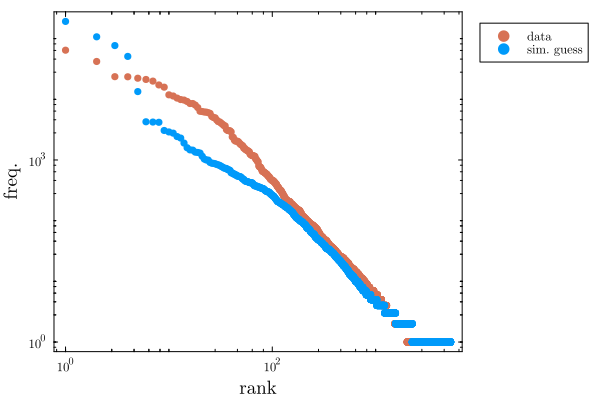

In [224]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

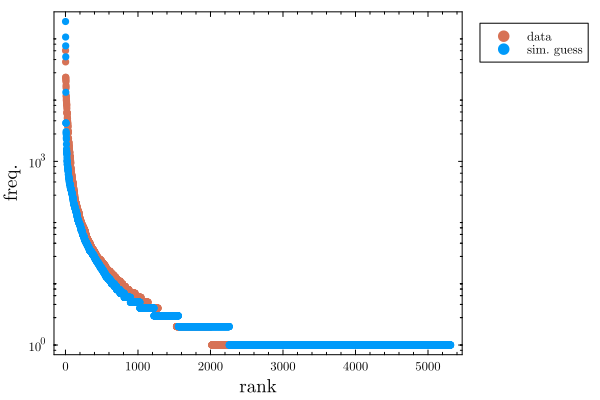

In [225]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

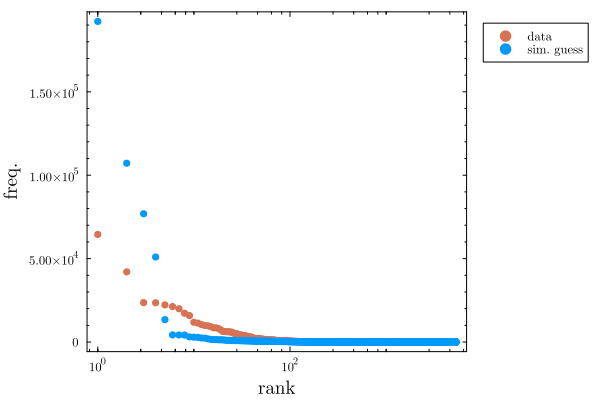

In [226]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)